# 14 Preprocessing Segments 

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from woofdata.path import data_path, load_data_dir_from_env_file

from woofdecoder.preprocess.bark_detector import load_bark_detector, settings_from_config
from woofdecoder.config import load_config
from woofdecoder.preprocess.bark_segments import build_segments
from woofdecoder.preprocess.media import TARGET_SAMPLE_RATE, load_audio_16k

## Loading necessary project files

In [2]:
load_data_dir_from_env_file()
VIDEO_PATH = data_path("test/media_test.mp4")

### Settings from pipeline.yaml

In [3]:
config = load_config()
settings = settings_from_config(config)
print(f"{settings}")

DetectionSettings(threshold=0.08, median_frames=1, max_gap_s=0.0, min_event_s=0.16)


### Loading Bark Detector

In [4]:
detector = load_bark_detector(config["bark_detector"]["model"], verbose=True)

dilation_list_t_dim: 
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
MN(
  (features): Sequential(
    (0): ConvNormActivation(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): ConvNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): ConvNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
        )
      )
    )
    (2): InvertedResidual(
      (block): Sequential(
        (0): Con

c:\Users\kimy8\Desktop\Deep Learning\dog-vocal-interpreter\.venv\Lib\site-packages\torchvision\ops\misc.py:121: UserWarning: Don't use ConvNormActivation directly, please use Conv2dNormActivation and Conv3dNormActivation instead.
  warnings.warn(


## Building Segments

In [5]:
segments = build_segments(VIDEO_PATH, detector, settings)

Building bark segments for media_test.mp4
Audio: 5.46 s
Scored 137 frames of 40 ms
Found 1 dog sounds (threshold 0.08)


C:\Users\kimy8\Desktop\Deep Learning\dog-vocal-interpreter\third_party\PretrainedSED\models\frame_passt\preprocess.py:129: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):


Segment 1/1:
  0.00  -  5.44s
dog vocalizing 0.70, 4 frames
growl         0.00  -  0.76s 0.50
bark          0.76  -  1.00s 0.62
growl         1.00  -  3.80s 0.81
bark          3.80  -  4.08s 0.61
growl         4.08  -  4.64s 0.69
bark          4.64  -  4.96s 0.62
growl         4.96  -  5.44s 0.60


### Summary of segment

In [6]:
print("Summary")
print(pd.DataFrame([{
    "start_s": round(s.start_s, 2),
    "end_s": round(s.end_s, 2),
    "length_s": round(s.duration_s, 2),
    "score": round(s.confidence, 2),
    "audio_samples": len(s.audio),
    "frames": len(s.frames)
} for s in segments]).to_string(index=False))

print("Segments")
rows = []
for number, segment in enumerate(segments, start=1):
    for label, (start_s, end_s), score in segment.sound_sections:
        rows.append({
            "segment": number,
            "dog_vocalizing": round(segment.confidence, 2),
            "sound": label,
            "start_s": start_s,
            "end_s": end_s,
            "length_s": round(end_s - start_s, 2),
            "score": round(score, 2)
        })

print(pd.DataFrame(rows).to_string(index=False))

Summary
 start_s  end_s  length_s  score  audio_samples  frames
     0.0   5.44      5.44    0.7          87040       4
Segments
 segment  dog_vocalizing sound  start_s  end_s  length_s  score
       1             0.7 growl     0.00   0.76      0.76   0.50
       1             0.7  bark     0.76   1.00      0.24   0.62
       1             0.7 growl     1.00   3.80      2.80   0.81
       1             0.7  bark     3.80   4.08      0.28   0.61
       1             0.7 growl     4.08   4.64      0.56   0.69
       1             0.7  bark     4.64   4.96      0.32   0.62
       1             0.7 growl     4.96   5.44      0.48   0.60


## Segment Audio Preview

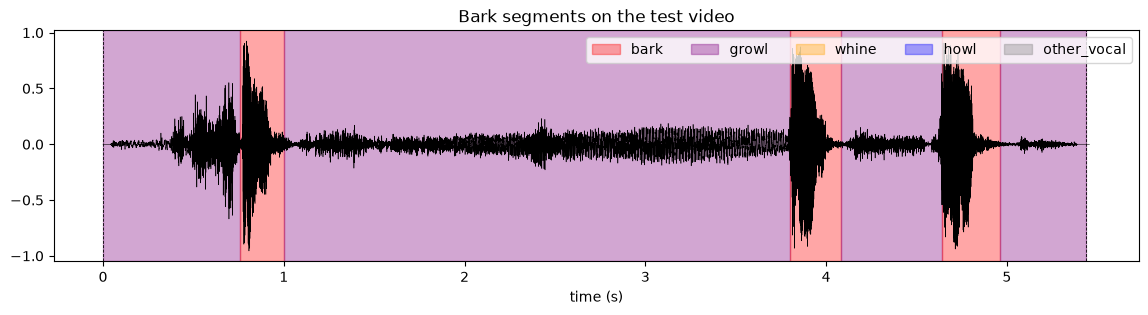

In [7]:
audio = load_audio_16k(VIDEO_PATH, verbose=False)
seconds = np.arange(len(audio)) / TARGET_SAMPLE_RATE
colors = {"bark": "red", "growl": "purple", "whine": "orange", "howl": "blue", "other_vocal": "gray"}

plt.figure(figsize=(14, 3))
plt.plot(seconds, audio, linewidth=0.4, color="black")
for segment in segments:
    for label, (start_s, end_s), _ in segment.sound_sections:
        plt.axvspan(start_s, end_s, color=colors[label], alpha=0.35)
    plt.axvline(segment.start_s, color="black", linewidth=0.6, linestyle="--")
    plt.axvline(segment.end_s, color="black", linewidth=0.6, linestyle="--")
    
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.35) for c in colors.values()]
plt.legend(handles, colors.keys(), ncol=5, loc="upper right")
plt.xlabel("time (s)")
plt.title("Bark segments on the test video")
plt.show()

## Segment Frames Preview

In [9]:
def section_at(segment, time_s):
    for section in segment.sound_sections:
        start_s, end_s = section.span_s
        if start_s <= time_s < end_s:
            return section
    
    return None

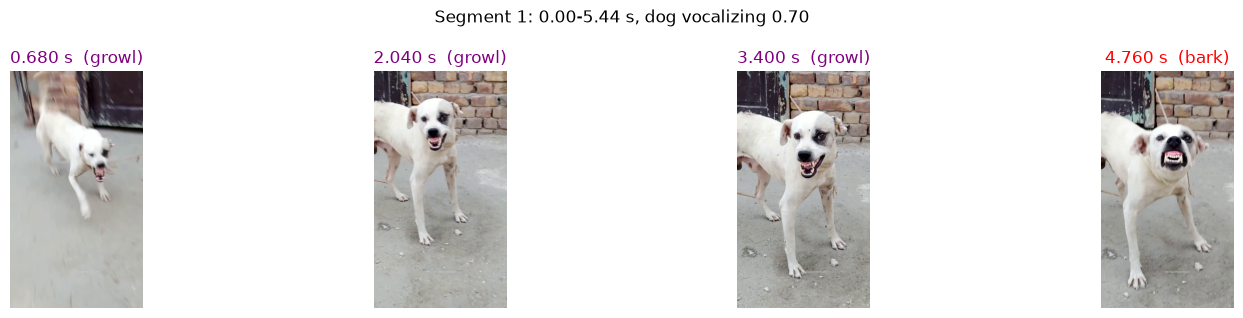

Frame size: (1920, 1080, 3) (height, width, 3)


In [10]:
for number, segment in enumerate(segments, start=1):
    if not segment.has_video:
        print(f"Segment {number}: no frames")
        continue
    
    figure, axes = plt.subplots(1, len(segment.frames), figsize=(4 * len(segment.frames), 3.2))
    figure.suptitle(f"Segment {number}: {segment.start_s:.2f}-{segment.end_s:.2f} s, "
                    f"dog vocalizing {segment.confidence:.2f}")
    for axis, frame, time_s in zip(np.atleast_1d(axes), segment.frames, segment.frame_times_s):
        section = section_at(segment, time_s)
        label = section.label if section else "?"
        axis.imshow(frame)
        axis.set_title(f"{time_s:.3f} s  ({label})", color=colors.get(label, "black"))
        axis.axis("off")
    plt.tight_layout()
    plt.show()
 
print(f"Frame size: {segments[0].frames[0].shape} (height, width, 3)" if segments and segments[0].has_video else "")